In [1]:
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt 
import seaborn as sns 

In [5]:
df_index = pd.read_csv("economic_index.csv")

In [6]:
df_index.head()

,Unnamed: 0,year,month,interest_rate,unemployment_rate,index_price
0,0,2017,12,2.75,5.3,1464
1,1,2017,11,2.50,5.3,1394
2,2,2017,10,2.50,5.3,1357
3,3,2017,9,2.50,5.3,1293
4,4,2017,8,2.50,5.4,1256


In [8]:
## drop unnecessary columns 

df_index.drop(columns=["Unnamed: 0" , "year" , "month"] , axis = 1 , inplace = True)

In [9]:
df_index.head()

,interest_rate,unemployment_rate,index_price
0,2.75,5.3,1464
1,2.50,5.3,1394
2,2.50,5.3,1357
3,2.50,5.3,1293
4,2.50,5.4,1256


In [12]:
df_index.isnull().sum()

interest_rate        0
unemployment_rate    0
index_price          0
dtype: int64

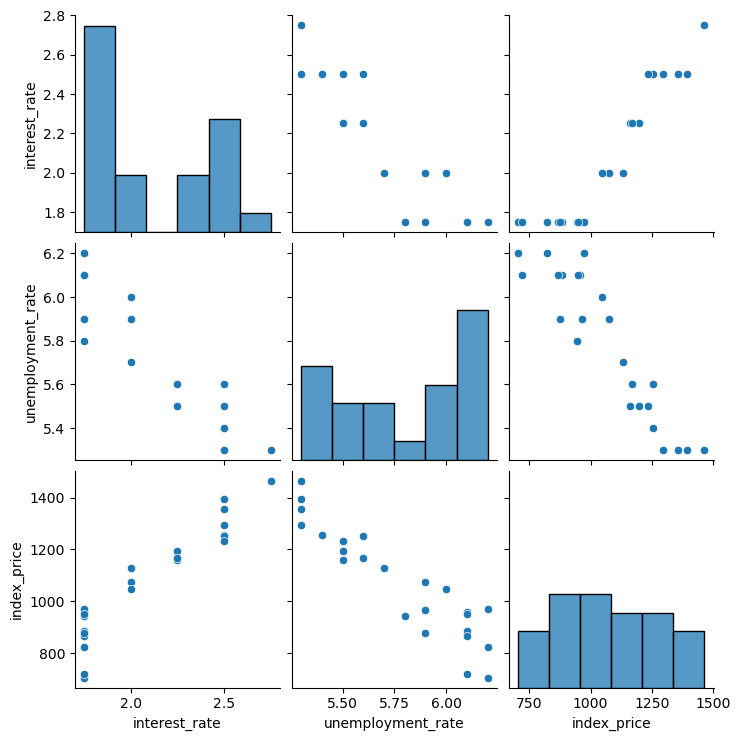

In [13]:
### lets do some visualization 

sns.pairplot(df_index)

In [14]:
df_index.corr()

,interest_rate,unemployment_rate,index_price
interest_rate,1.000000,-0.925814,0.935793
unemployment_rate,-0.925814,1.000000,-0.922338
index_price,0.935793,-0.922338,1.000000


Text(0, 0.5, 'Unemployment_rate')

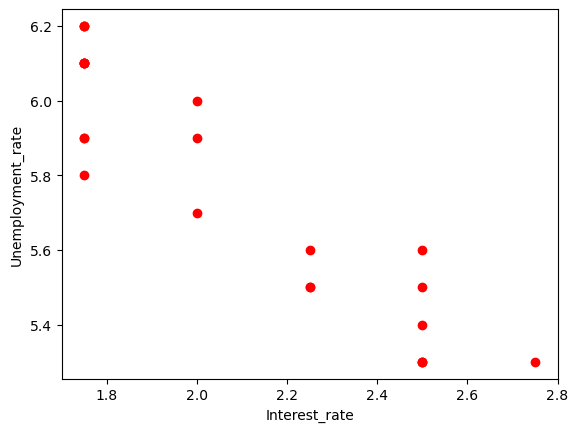

In [17]:
## visulize the data point more closely 

plt.scatter(df_index['interest_rate'],df_index['unemployment_rate'],color = 'r')
plt.xlabel("Interest_rate")
plt.ylabel("Unemployment_rate")

In [18]:
## Independent and dependent rate 


X = df_index.iloc[:,:-1]
y = df_index.iloc[:,-1]

In [19]:
X.head()

,interest_rate,unemployment_rate
0,2.75,5.3
1,2.50,5.3
2,2.50,5.3
3,2.50,5.3
4,2.50,5.4


In [20]:
y


0     1464
1     1394
2     1357
3     1293
4     1256
5     1254
6     1234
7     1195
8     1159
9     1167
10    1130
11    1075
12    1047
13     965
14     943
15     958
16     971
17     949
18     884
19     866
20     876
21     822
22     704
23     719
Name: index_price, dtype: int64

In [32]:
## train test split 

from sklearn.model_selection import train_test_split 
X_train , X_test , y_train , y_test = train_test_split(X , y , test_size = 0.25 , random_state = 42)

<Axes: xlabel='interest_rate', ylabel='index_price'>

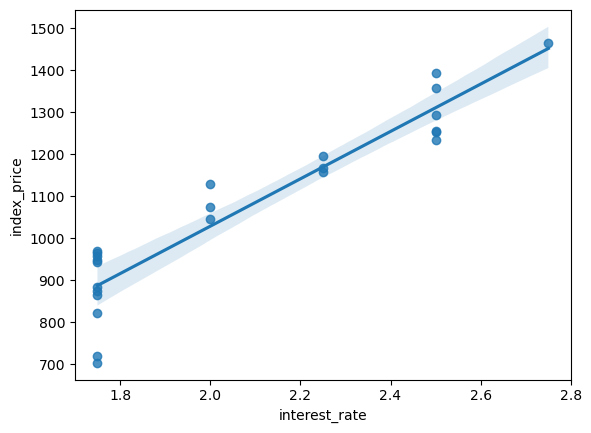

In [33]:
sns.regplot(x = df_index["interest_rate"] , y = df_index['index_price'])

<Axes: xlabel='interest_rate', ylabel='unemployment_rate'>

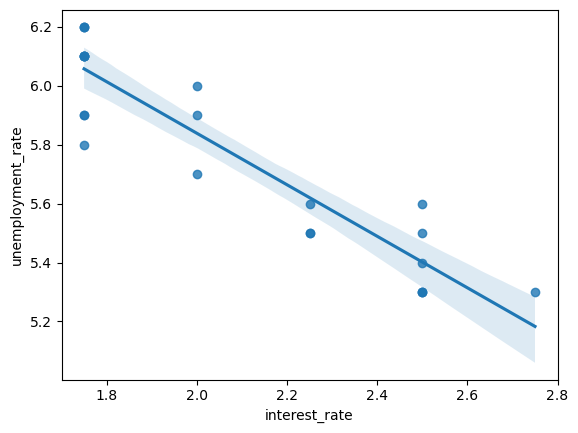

In [34]:
sns.regplot(x = df_index["interest_rate"] , y = df_index['unemployment_rate'])

<Axes: xlabel='index_price', ylabel='unemployment_rate'>

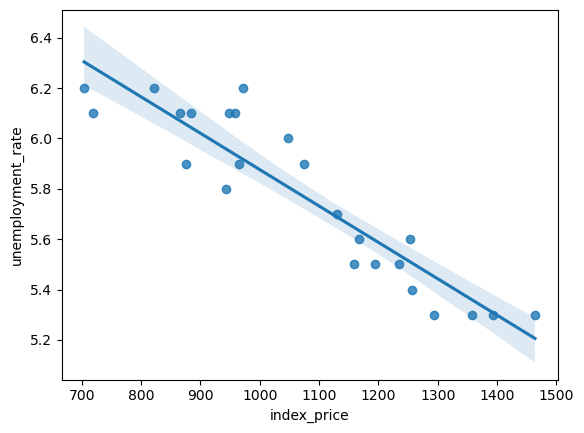

In [35]:
sns.regplot(x = df_index["index_price"] , y = df_index['unemployment_rate'])

In [62]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
x_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

C:\Users\yogen\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


In [63]:
X_test

array([[ -4.99717773, -20.46612696],
       [ -9.25773166, -13.78355021],
       [ -0.7366238 , -22.37543461],
       [ -9.25773166, -14.73820403],
       [ -7.1274547 , -16.64751167],
       [ -4.99717773, -19.51147314]])

In [64]:
from sklearn.linear_model import LinearRegression 

regression = LinearRegression()


In [65]:
regression.fit(X_train , y_train)

LinearRegression()

In [66]:
from sklearn.model_selection import cross_val_score
validation_score = cross_val_score(regression , X_train , y_train , scoring = 'neg_mean_squared_error',cv=3)

In [67]:
validation_score 


array([-4921.61331265, -7686.87497294, -5135.9962549 ])

In [68]:
np.mean(validation_score)

np.float64(-5914.828180162406)

In [69]:
## prediction 
y_pred = regression.predict(X_test)

C:\Users\yogen\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


In [70]:
y_pred

array([ 8680.48250057,  5161.67355935, 10478.12806785,  5505.90623414,
        6748.96169256,  8336.24982578])

In [71]:
from sklearn.metrics import mean_absolute_error , mean_squared_error 
mae = mean_absolute_error(y_pred , y_test)
mse = mean_squared_error(y_pred , y_test)
rmse = np.sqrt(mse)
print(mse)
print(mae)
print(rmse)

43390491.71687887
6365.233646708195
6587.145946225791


In [75]:
from sklearn.metrics import r2_score 

score = r2_score(y_test , y_pred)
print(score)

-1287.9030551382916


### Assumptions

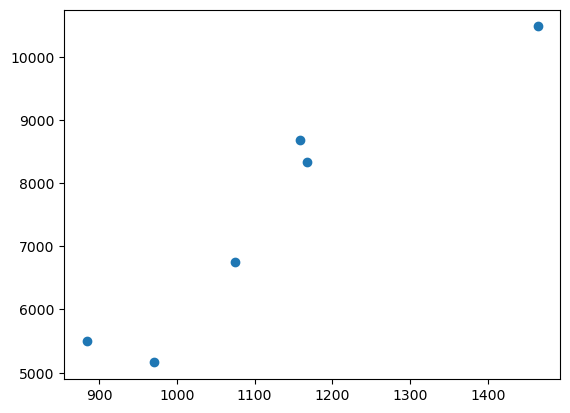

In [76]:
plt.scatter(y_test , y_pred)

In [78]:
residuals = y_test - y_pred
print(residuals)

8    -7521.482501
16   -4190.673559
0    -9014.128068
18   -4621.906234
11   -5673.961693
9    -7169.249826
Name: index_price, dtype: float64


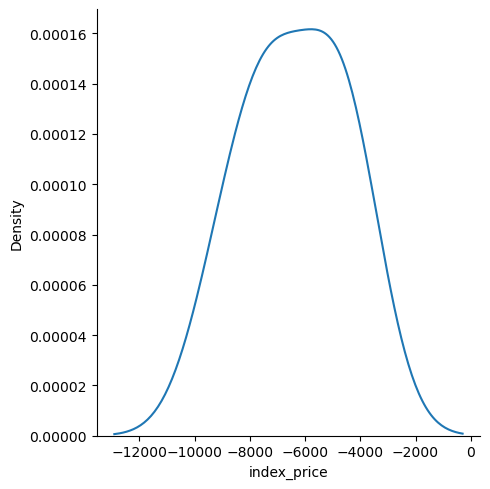

In [80]:
## plot this residuals 
sns.displot(residuals ,  kind = "kde")

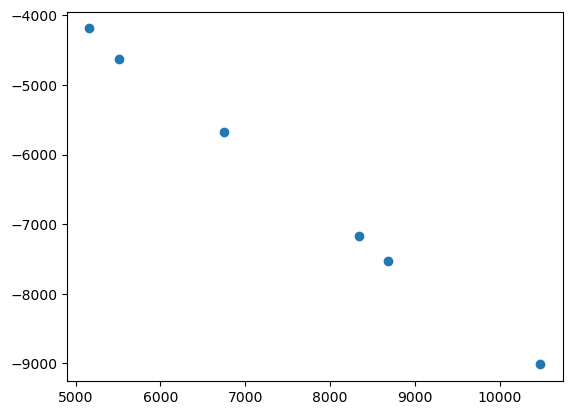

In [83]:
## scattter plot with respect to prediction and residuals 
plt.scatter(y_pred , residuals)

In [88]:
##OLS linear regression 
import statsmodels.api as sm 
model = sm.OLS(y_train , X_train).fit()

In [89]:
prediction = model.predict(X_test)
print(prediction)

[-2427.08051327 -4992.86421664    40.50075165 -4973.22372895
 -3719.7926088  -2446.72100096]


In [90]:
model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                                 OLS Regression Results                                
=======================================================================================
Dep. Variable:            index_price   R-squared (uncentered):                   0.995
Model:                            OLS   Adj. R-squared (uncentered):              0.994
Method:                 Least Squares   F-statistic:                              1468.
Date:                Sun, 01 Nov 2026   Prob (F-statistic):                    7.46e-19
Time:                        18:29:32   Log-Likelihood:                         -104.21
No. Observations:                  18   AIC:                                      212.4
Df Residuals:                      16   BIC:                                      214.2
Df Model:                           2                                                  
Covariance Type:            nonrobust                                                  
=====================================================================================
                        coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------
interest_rate       569.9494     44.349     12.851      0.000     475.933     663.965
unemployment_rate   -20.5734     15.966     -1.289      0.216     -54.421      13.274
==============================================================================
Omnibus:                        1.657   Durbin-Watson:                   1.707
Prob(Omnibus):                  0.437   Jarque-Bera (JB):                1.346
Skew:                          -0.611   Prob(JB):                        0.510
Kurtosis:                       2.451   Cond. No.                         14.6
==============================================================================

Notes:
[1] R² is computed without centering (uncentered) since the model does not contain a constant.
[2] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""